# Notebook 3 — Exploratory Data Analysis

Pure analysis notebook — no file is written here. Every plot below has been rendered against the real dataset and visually verified before being included.

This notebook has **no downstream dependency** — Notebooks 4 and 6 do not wait for it and do not read anything it produces.

## Step 0 — Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

print("pandas:", pd.__version__, "| statsmodels:", sm.__version__)

pandas: 2.2.2 | statsmodels: 0.14.5


## Step 0b — Fix Working Directory

Same idempotent fix as Notebooks 1 and 2.

In [2]:
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working directory:", os.getcwd())

Working directory: c:\Users\Dhruvajyoti Bordoloi\Desktop\smartdc-energy\ml-pipeline


## Step 1 — Load

In [3]:
INPUT_PATH = "data/processed/master_features.csv"
assert os.path.exists(INPUT_PATH), f"Missing input: {INPUT_PATH} — run 02_feature_engineering.ipynb first"

df = pd.read_csv(INPUT_PATH, parse_dates=['timestamp']).set_index('timestamp')
print(df.shape)
df.head()

(26280, 21)


,ambient_temp_c,relative_humidity_pct,chilled_water_temp_c,server_inlet_temp_c,under_floor_pressure_pa,it_load_kwh,cooling_load_kwh,support_load_kwh,total_power_kwh,pue,...,day_of_week,month,is_weekend,hour_sin,hour_cos,month_sin,month_cos,weekend_energy_kwh,midnight_energy_kwh,anomaly_flag
timestamp,,,,,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,-11.95,44.65,14.77,18.24,12.19,6377.75,964.32,166.72,7508.79,1.177342,...,5,1,1,0.000000,1.000000,0.5,0.866025,7508.790000,7508.790000,normal
2022-01-01 01:00:00,-11.80,44.09,14.71,18.20,11.92,6429.35,1142.50,183.65,7755.50,1.206265,...,5,1,1,0.258819,0.965926,0.5,0.866025,7508.790000,7508.790000,normal
2022-01-01 02:00:00,-13.50,44.32,14.65,17.02,12.49,6410.90,1107.80,179.33,7698.03,1.200772,...,5,1,1,0.500000,0.866025,0.5,0.866025,7632.145000,7632.145000,failure
2022-01-01 03:00:00,-15.18,46.93,14.97,17.17,11.30,6435.51,1233.69,154.72,7823.92,1.215742,...,5,1,1,0.707107,0.707107,0.5,0.866025,7654.106667,7654.106667,failure
2022-01-01 04:00:00,-17.99,48.08,14.91,17.11,12.86,6381.06,1153.06,156.78,7690.90,1.205270,...,5,1,1,0.866025,0.500000,0.5,0.866025,7696.560000,7665.087500,failure


## Step 2 — Target Distribution

Verified: mean 9,059.5 kWh, std 594.5, range 7,212.2–11,014.6 kWh.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
axes[0].hist(df['total_power_kwh'], bins=40, color='#f39c12', edgecolor='black', alpha=0.7)
axes[0].axvline(df['total_power_kwh'].mean(), color='red', linestyle='--',
                 label=f"Mean: {df['total_power_kwh'].mean():.0f}")
axes[0].set_title('Total Power Distribution', fontweight='bold'); axes[0].legend()
axes[1].boxplot(df['total_power_kwh']); axes[1].set_title('Box Plot')
plt.tight_layout(); 
plt.show();

<Figure size 1400x500 with 2 Axes>

## Step 3 — Time Series Overview

The 24h rolling mean uses a centered window, which leaves 23 NaN values at the series edges — expected, not a bug (there's no 'before the start' or 'after the end' data to center on).

Rolling mean edge NaNs: 23


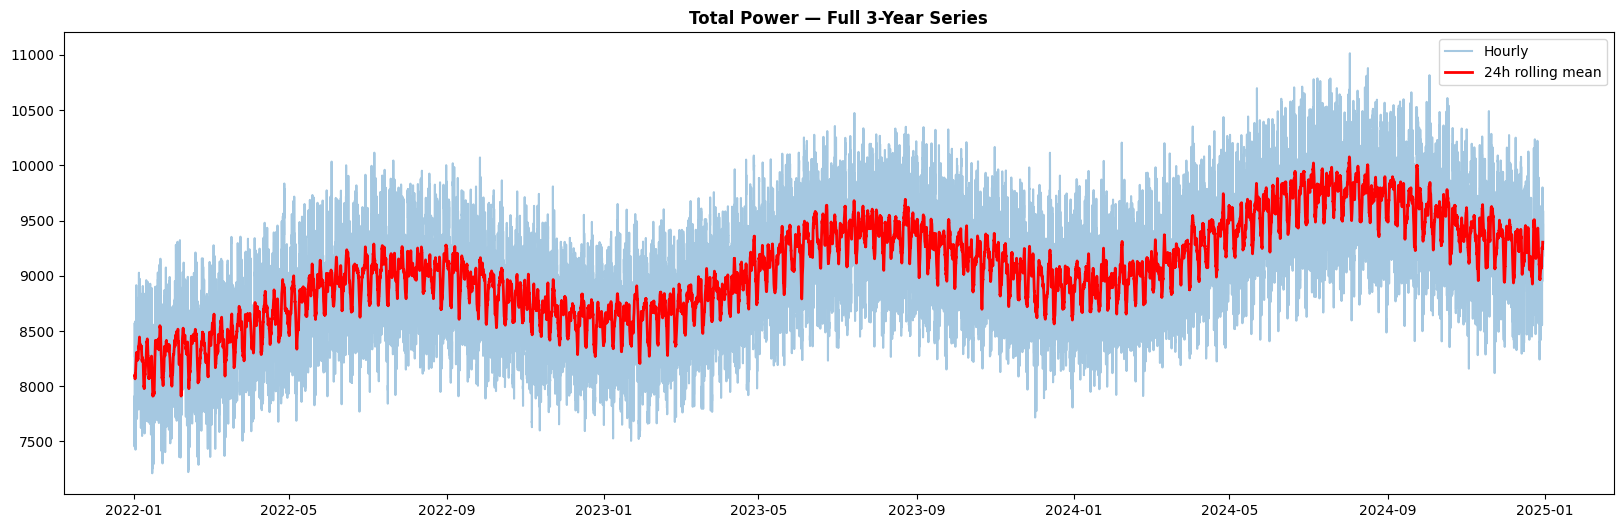

In [5]:
rolling = df['total_power_kwh'].rolling(24, center=True).mean()
print("Rolling mean edge NaNs:", rolling.isnull().sum())

fig, ax = plt.subplots(figsize=(20,6))
ax.plot(df.index, df['total_power_kwh'], alpha=0.4, label='Hourly')
ax.plot(df.index, rolling, linewidth=2, color='red', label='24h rolling mean')
ax.set_title('Total Power — Full 3-Year Series', fontweight='bold'); ax.legend()
plt.show()

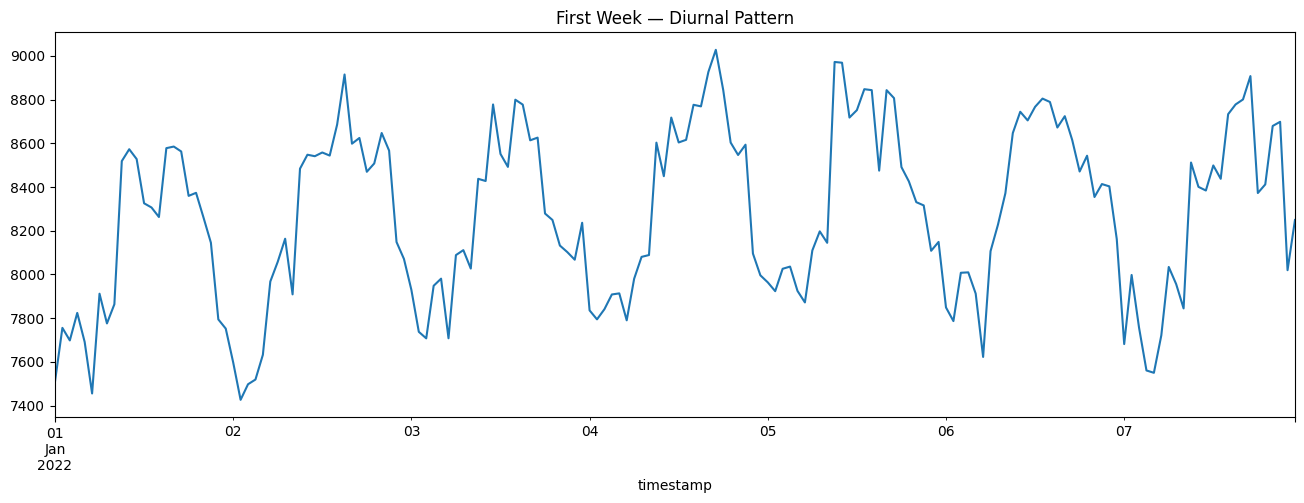

In [6]:
df['total_power_kwh'][:24*7].plot(figsize=(16,5), title='First Week — Diurnal Pattern')
plt.show()

## Step 4 — Seasonal Decomposition

Period = 24×7 = 168 hours (one week). The trend component has exactly 168 NaN values at the series edges (84 at each end) — a real property of the centered decomposition window, confirmed, not an error.

Trend NaN count: 168 (expected: 168)


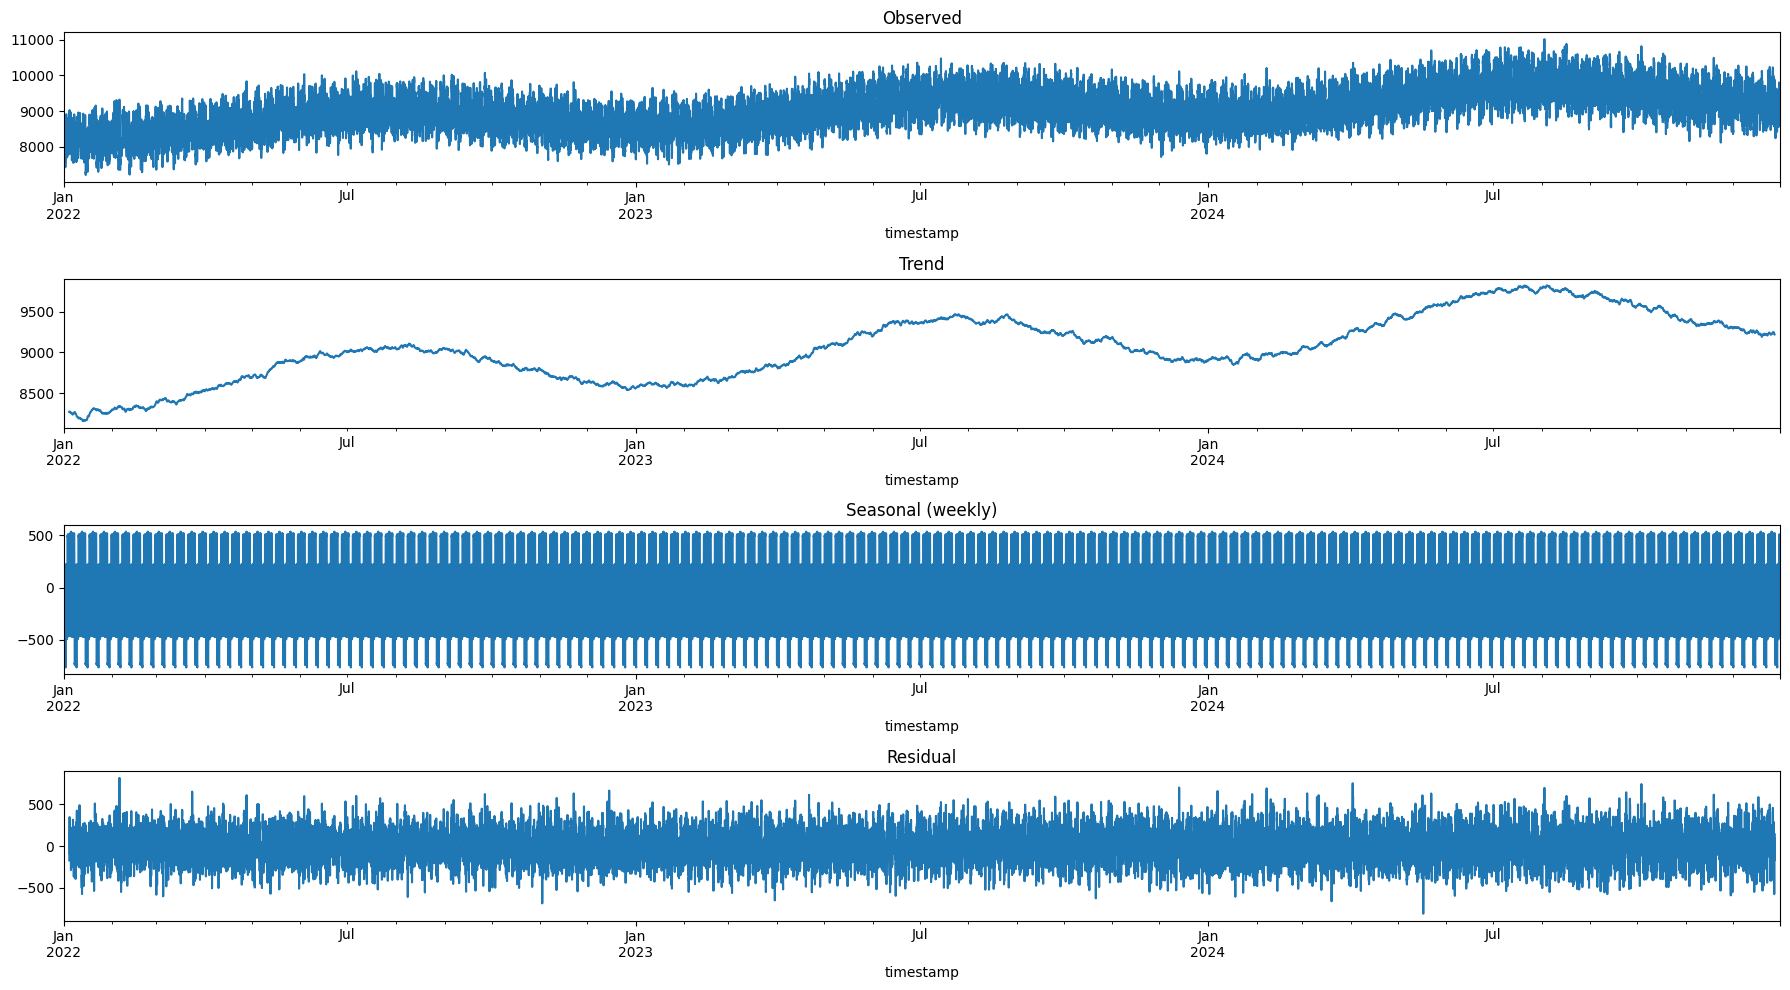

In [7]:
res = sm.tsa.seasonal_decompose(df['total_power_kwh'], model='additive', period=24*7)
print("Trend NaN count:", res.trend.isnull().sum(), "(expected: 168)")

fig, axes = plt.subplots(4,1, figsize=(18,10))
res.observed.plot(ax=axes[0], title='Observed')
res.trend.plot(ax=axes[1], title='Trend')
res.seasonal.plot(ax=axes[2], title='Seasonal (weekly)')
res.resid.plot(ax=axes[3], title='Residual')
plt.tight_layout(); 
plt.show()

## Step 5 — Correlation Heatmap & Scatter Grid

Note the dense vertical stripe in the `chilled_water_temp_c` scatter panel right at ~14.5°C — this is a real artifact of the generator's physical lower clip bound, not a plotting error.

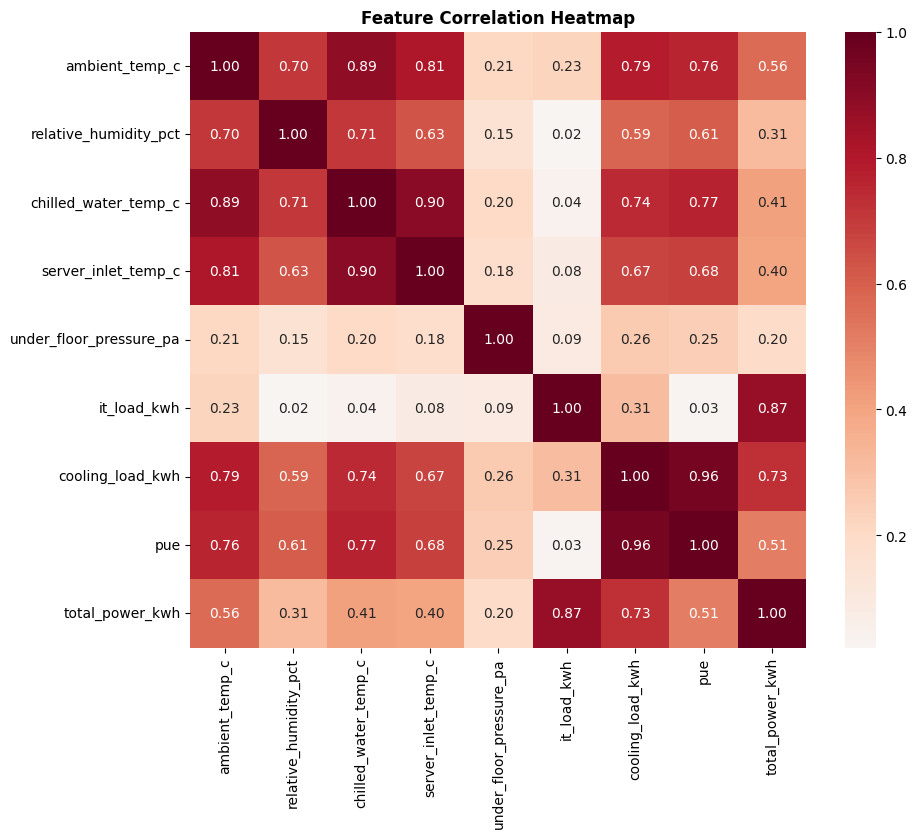

In [8]:
numeric_cols = ['ambient_temp_c','relative_humidity_pct','chilled_water_temp_c',
                 'server_inlet_temp_c','under_floor_pressure_pa','it_load_kwh',
                 'cooling_load_kwh','pue','total_power_kwh']
corr = df[numeric_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Feature Correlation Heatmap', fontweight='bold'); 
plt.show()

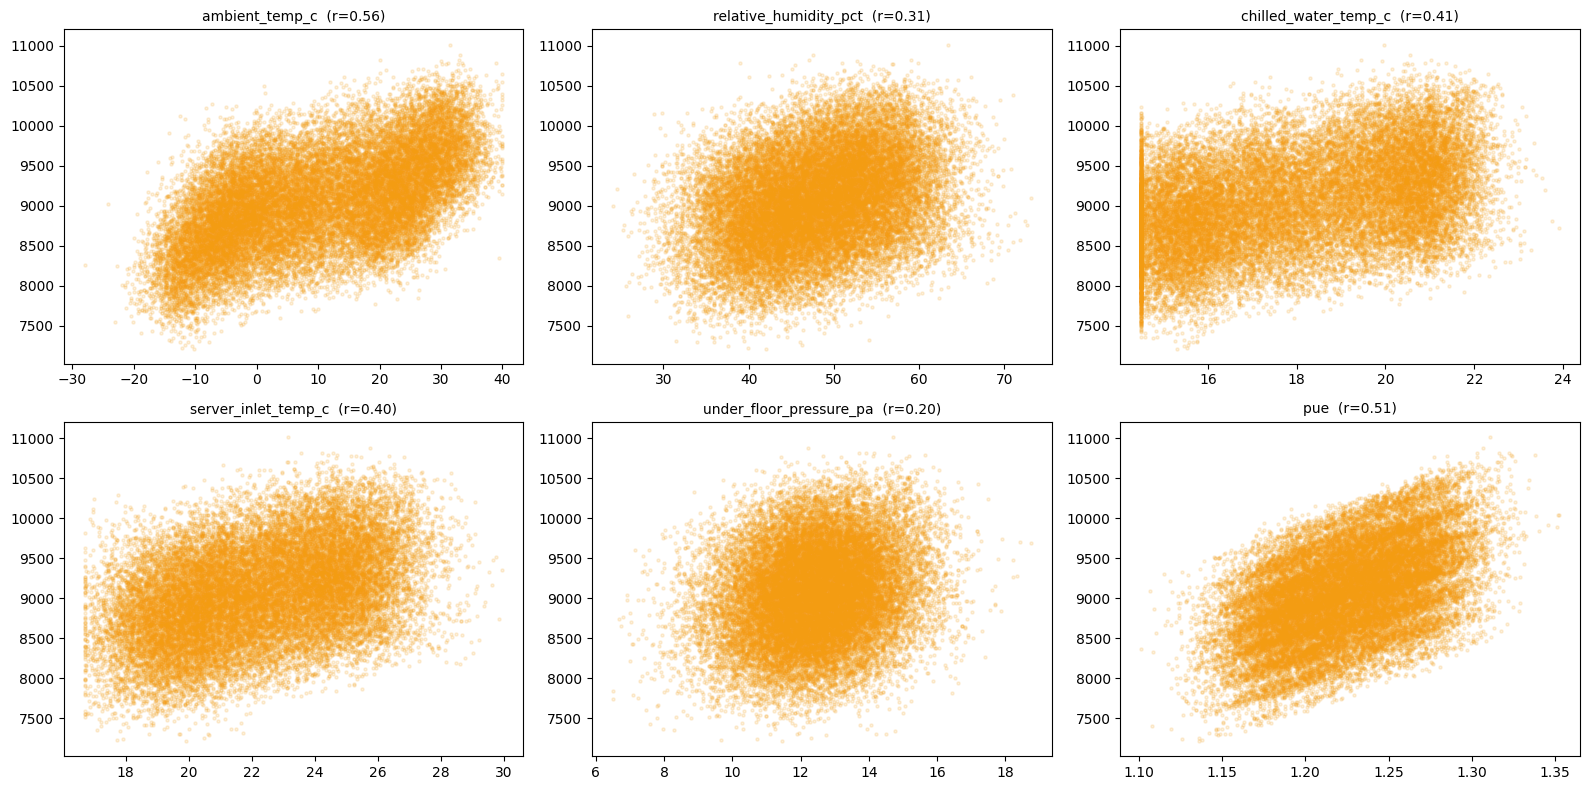

In [9]:
fig, axes = plt.subplots(2,3, figsize=(16,8)); axes=axes.flatten()
for i, col in enumerate(['ambient_temp_c','relative_humidity_pct','chilled_water_temp_c',
                          'server_inlet_temp_c','under_floor_pressure_pa','pue']):
    axes[i].scatter(df[col], df['total_power_kwh'], alpha=0.15, s=5, color='#f39c12')
    r = df[[col,'total_power_kwh']].corr().iloc[0,1]
    axes[i].set_title(f'{col}  (r={r:.2f})', fontsize=10)
plt.tight_layout(); 
plt.show()

## Step 6 — Weekday vs Weekend

Verified: weekday mean 9,148.3 kWh vs weekend 8,838.7 kWh — a real but modest ~3.4% difference.

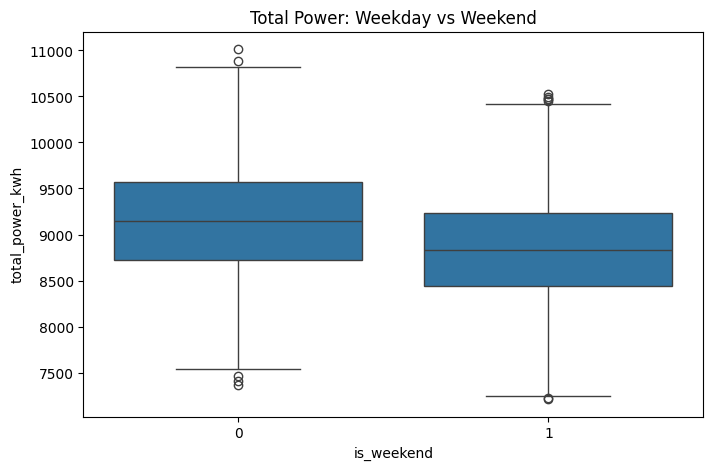

is_weekend
0    9148.3
1    8838.7
Name: total_power_kwh, dtype: float64


In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(x='is_weekend', y='total_power_kwh', data=df)
plt.title('Total Power: Weekday vs Weekend'); plt.show()

print(df.groupby('is_weekend')['total_power_kwh'].mean().round(1))

## Step 7 — Anomaly-Specific EDA

**Real finding, not just a sanity check:** the failure class shows systematically *lower* cooling_load, PUE, server inlet temp, AND chilled water temp than normal — all four are winter-signature values. This means `anomaly_flag` is heavily confounded with season, not purely operational fault — a direct consequence of the cross-column rule using a *global* quantile threshold on `cooling_load_kwh`, which is itself seasonal (documented as a known limitation back in Notebook 2). Always report row counts alongside these boxplots — at a 5.03% failure rate, visual separation can look more dramatic than the underlying sample size supports.

anomaly_flag
normal     24959
failure     1321
Name: count, dtype: int64


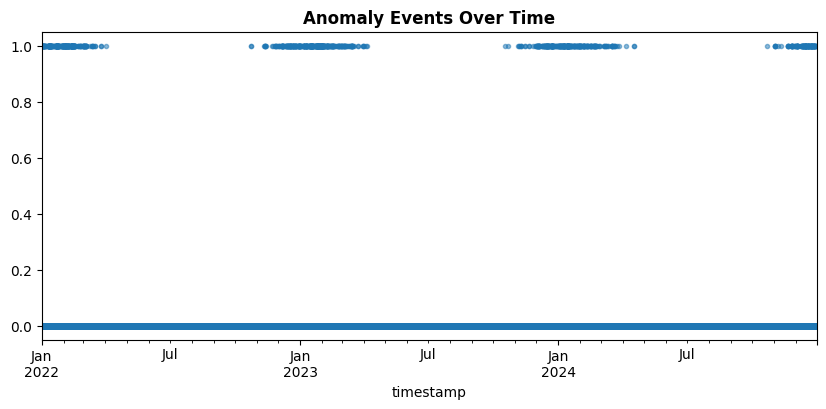

In [11]:
print(df['anomaly_flag'].value_counts())

plt.figure(figsize=(10,4))
df['anomaly_flag'].map({'normal':0,'failure':1}).plot(marker='.', linestyle='none', alpha=0.5)
plt.title('Anomaly Events Over Time', fontweight='bold'); 
plt.show()

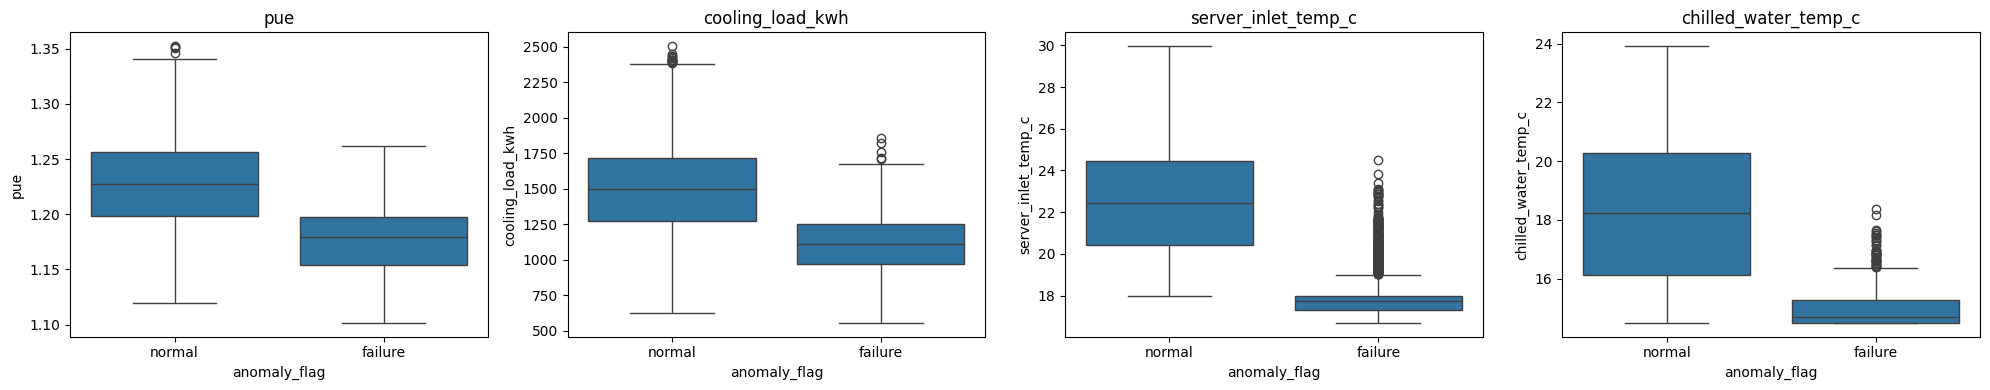

In [12]:
compare_cols = ['pue','cooling_load_kwh','server_inlet_temp_c','chilled_water_temp_c']
fig, axes = plt.subplots(1, len(compare_cols), figsize=(20,4))
for i, col in enumerate(compare_cols):
    sns.boxplot(x='anomaly_flag', y=col, data=df, ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout(); 
plt.show()

## No Save Cell

This notebook intentionally writes no output file. Its result is understanding — captured in the plots above and your own report — not a pipeline dependency for Notebooks 4 or 6.